In [1]:
!pip install duckdb pyarrow

   ---------------------------------------- 0.0/15.4 MB ? eta -:--:--
   ----- ---------------------------------- 2.1/15.4 MB 18.7 MB/s eta 0:00:01
   ------------------- -------------------- 7.3/15.4 MB 21.5 MB/s eta 0:00:01
   --------------------------- ------------ 10.5/15.4 MB 19.2 MB/s eta 0:00:01
   ---------------------------------------  15.2/15.4 MB 19.8 MB/s eta 0:00:01
   ---------------------------------------- 15.4/15.4 MB 19.0 MB/s  0:00:00


In [2]:
import duckdb
from pathlib import Path

path = Path(r"..\data\accepted_2007_to_2018q4.csv\accepted_2007_to_2018Q4.csv")
print(path.resolve())
print("File found:", path.exists())

C:\Users\ANTARA BASAK\Documents\risk-projects\data\accepted_2007_to_2018q4.csv\accepted_2007_to_2018Q4.csv
File found: False


In [3]:
import duckdb
from pathlib import Path

root = Path(r"C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data")
files = list(root.rglob("*.csv"))
for f in files:
    print(f, "|", round(f.stat().st_size / 1e9, 2), "GB")

C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data\accepted_2007_to_2018q4.csv | 0.0 GB
C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data\accepted_2007_to_2018q4.csv\accepted_2007_to_2018Q4.csv | 1.68 GB


In [4]:
path = Path(r"C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data")
print(path.resolve())
print("File found:", path.exists())

C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data
File found: True


In [5]:
path = files[0]
con = duckdb.connect()
con.sql(f"""
    CREATE VIEW src AS
    SELECT * FROM read_csv('{path}', header=true, all_varchar=true, ignore_errors=true)
""")
con.sql("SELECT count(*) AS n_rows FROM src").show()

┌─────────┐
│ n_rows  │
│  int64  │
├─────────┤
│ 2260701 │
└─────────┘



In [6]:
con.sql(f"""
    COPY (SELECT * FROM src WHERE try_strptime(issue_d, '%b-%Y') IS NOT NULL)
    TO '{root / "accepted.parquet"}' (FORMAT PARQUET)
""")
print("Saved")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved


In [7]:
pq = root / "accepted.parquet"
print(round(pq.stat().st_size / 1e6), "MB")
con.sql(f"CREATE OR REPLACE VIEW acc AS SELECT * FROM read_parquet('{pq}')")
con.sql("SELECT count(*) AS n_rows FROM acc").show()

414 MB
┌─────────┐
│ n_rows  │
│  int64  │
├─────────┤
│ 2260668 │
└─────────┘



In [8]:
con.sql("SELECT loan_status, count(*) AS n FROM acc GROUP BY 1 ORDER BY 2 DESC").show()

┌─────────────────────────────────────────────────────┬─────────┐
│                     loan_status                     │    n    │
│                       varchar                       │  int64  │
├─────────────────────────────────────────────────────┼─────────┤
│ Fully Paid                                          │ 1076751 │
│ Current                                             │  878317 │
│ Charged Off                                         │  268559 │
│ Late (31-120 days)                                  │   21467 │
│ In Grace Period                                     │    8436 │
│ Late (16-30 days)                                   │    4349 │
│ Does not meet the credit policy. Status:Fully Paid  │    1988 │
│ Does not meet the credit policy. Status:Charged Off │     761 │
│ Default                                             │      40 │
└─────────────────────────────────────────────────────┴─────────┘



In [9]:
con.sql("""
    SELECT year(strptime(issue_d, '%b-%Y')) AS issue_year, count(*) AS n
    FROM acc GROUP BY 1 ORDER BY 1
""").show()

┌────────────┬────────┐
│ issue_year │   n    │
│   int64    │ int64  │
├────────────┼────────┤
│       2007 │    603 │
│       2008 │   2393 │
│       2009 │   5281 │
│       2010 │  12537 │
│       2011 │  21721 │
│       2012 │  53367 │
│       2013 │ 134814 │
│       2014 │ 235629 │
│       2015 │ 421095 │
│       2016 │ 434407 │
│       2017 │ 443579 │
│       2018 │ 495242 │
└────────────┴────────┘
  12 rows   2 columns



In [10]:
con.sql("""
    CREATE OR REPLACE TABLE labeled AS
    SELECT *,
           CASE WHEN loan_status = 'Fully Paid' THEN 0
                WHEN loan_status IN ('Charged Off','Default') THEN 1 END AS default_flag,
           year(strptime(issue_d,'%b-%Y')) AS issue_year
    FROM acc
    WHERE loan_status IN ('Fully Paid','Charged Off','Default')
""")
con.sql("SELECT default_flag, count(*) AS n FROM labeled GROUP BY 1").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────┬─────────┐
│ default_flag │    n    │
│    int32     │  int64  │
├──────────────┼─────────┤
│            0 │ 1076751 │
│            1 │  268599 │
└──────────────┴─────────┘



In [11]:
con.sql("""
    SELECT issue_year, term, count(*) AS n, round(avg(default_flag),3) AS default_rate
    FROM labeled GROUP BY 1,2 ORDER BY 1,2
""").show(max_rows=40)

┌────────────┬────────────┬────────┬──────────────┐
│ issue_year │    term    │   n    │ default_rate │
│   int64    │  varchar   │ int64  │    double    │
├────────────┼────────────┼────────┼──────────────┤
│       2007 │  36 months │    251 │        0.179 │
│       2008 │  36 months │   1562 │        0.158 │
│       2009 │  36 months │   4716 │        0.126 │
│       2010 │  36 months │   8466 │        0.099 │
│       2010 │  60 months │   3070 │         0.21 │
│       2011 │  36 months │  14101 │        0.106 │
│       2011 │  60 months │   7620 │        0.236 │
│       2012 │  36 months │  43470 │        0.136 │
│       2012 │  60 months │   9897 │        0.277 │
│       2013 │  36 months │ 100422 │        0.123 │
│       2013 │  60 months │  34382 │        0.251 │
│       2014 │  36 months │ 162570 │        0.137 │
│       2014 │  60 months │  60533 │        0.311 │
│       2015 │  36 months │ 283026 │        0.149 │
│       2015 │  60 months │  92520 │        0.364 │
│       2016

In [12]:
con.sql(f"COPY labeled TO '{root / 'labeled.parquet'}' (FORMAT PARQUET)")
print("Saved labeled.parquet")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved labeled.parquet


In [13]:
con.sql("""
    SELECT issue_year, count(*) AS n, round(avg(default_flag),3) AS default_rate
    FROM labeled WHERE trim(term) = '36 months'
    GROUP BY 1 ORDER BY 1
""").df()

,issue_year,n,default_rate
0,2007,251,0.179
1,2008,1562,0.158
2,2009,4716,0.126
3,2010,8466,0.099
4,2011,14101,0.106
5,2012,43470,0.136
6,2013,100422,0.123
7,2014,162570,0.137
8,2015,283026,0.149
9,2016,232361,0.198


In [14]:
con.sql(f"COPY labeled TO '{root / 'labeled.parquet'}' (FORMAT PARQUET)")
print("Saved labeled.parquet")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved labeled.parquet


In [15]:
con.sql("""
    SELECT year(strptime(issue_d,'%b-%Y')) AS issue_year,
           count(*) AS all_loans,
           sum(CASE WHEN loan_status IN ('Fully Paid','Charged Off','Default') THEN 1 ELSE 0 END) AS final_outcome,
           round(avg(CASE WHEN loan_status IN ('Fully Paid','Charged Off','Default') THEN 1.0 ELSE 0 END),3) AS share_final
    FROM acc WHERE trim(term) = '36 months'
    GROUP BY 1 ORDER BY 1
""").df()

,issue_year,all_loans,final_outcome,share_final
0,2007,603,251.0,0.416
1,2008,2393,1562.0,0.653
2,2009,5281,4716.0,0.893
3,2010,9156,8466.0,0.925
4,2011,14101,14101.0,1.000
5,2012,43470,43470.0,1.000
6,2013,100422,100422.0,1.000
7,2014,162570,162570.0,1.000
8,2015,283173,283026.0,0.999
9,2016,323495,232361.0,0.718


In [16]:
con.sql("CREATE OR REPLACE TABLE dev AS SELECT * FROM labeled WHERE trim(term)='36 months' AND issue_year BETWEEN 2012 AND 2014")
con.sql("CREATE OR REPLACE TABLE oot AS SELECT * FROM labeled WHERE trim(term)='36 months' AND issue_year = 2015")
con.sql("""
    SELECT 'dev' AS sample, count(*) AS n, round(avg(default_flag),3) AS default_rate FROM dev
    UNION ALL
    SELECT 'oot', count(*), round(avg(default_flag),3) FROM oot
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,sample,n,default_rate
0,dev,306462,0.132
1,oot,283026,0.149


In [17]:
con.sql(f"COPY dev TO '{root / 'dev.parquet'}' (FORMAT PARQUET)")
con.sql(f"COPY oot TO '{root / 'oot.parquet'}' (FORMAT PARQUET)")
print("Saved dev and oot")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved dev and oot


In [18]:
cols = con.sql("DESCRIBE dev").df()['column_name'].tolist()
print(len(cols))
print(", ".join(cols))

153
id, member_id, loan_amnt, funded_amnt, funded_amnt_inv, term, int_rate, installment, grade, sub_grade, emp_title, emp_length, home_ownership, annual_inc, verification_status, issue_d, loan_status, pymnt_plan, url, desc, purpose, title, zip_code, addr_state, dti, delinq_2yrs, earliest_cr_line, fico_range_low, fico_range_high, inq_last_6mths, mths_since_last_delinq, mths_since_last_record, open_acc, pub_rec, revol_bal, revol_util, total_acc, initial_list_status, out_prncp, out_prncp_inv, total_pymnt, total_pymnt_inv, total_rec_prncp, total_rec_int, total_rec_late_fee, recoveries, collection_recovery_fee, last_pymnt_d, last_pymnt_amnt, next_pymnt_d, last_credit_pull_d, last_fico_range_high, last_fico_range_low, collections_12_mths_ex_med, mths_since_last_major_derog, policy_code, application_type, annual_inc_joint, dti_joint, verification_status_joint, acc_now_delinq, tot_coll_amt, tot_cur_bal, open_acc_6m, open_act_il, open_il_12m, open_il_24m, mths_since_rcnt_il, total_bal_il, il_ut

In [21]:
import pandas as pd
miss = []
for c in cols:
    try:
        r = con.sql(f"""SELECT avg(CASE WHEN "{c}" IS NULL OR trim(CAST("{c}" AS VARCHAR)) = '' THEN 1.0 ELSE 0 END) FROM dev""").fetchall()[0][0]
        miss.append((c, round(r, 3)))
    except Exception as e:
        print("skipped:", c, "|", str(e)[:80])
miss = pd.DataFrame(miss, columns=['column', 'missing_share']).sort_values('missing_share', ascending=False)
miss[miss.missing_share > 0.3]

,column,missing_share
1,member_id,1.000
129,hardship_type,1.000
127,sec_app_mths_since_last_major_derog,1.000
126,sec_app_collections_12_mths_ex_med,1.000
142,hardship_last_payment_amount,1.000
140,orig_projected_additional_accrued_interest,1.000
139,hardship_loan_status,1.000
57,annual_inc_joint,1.000
73,all_util,1.000
77,inq_last_12m,1.000


In [22]:
leak_exact = {'out_prncp','out_prncp_inv','total_pymnt','total_pymnt_inv','total_rec_prncp',
              'total_rec_int','total_rec_late_fee','recoveries','collection_recovery_fee',
              'pymnt_plan','funded_amnt','funded_amnt_inv','policy_code'}
leak_prefix = ('hardship_','settlement_','debt_settlement','orig_projected','payment_plan_start',
               'deferral_term','disbursement_method','last_','next_pymnt')
skip_exact = {'id','member_id','url','desc','emp_title','title','zip_code',
              'issue_d','issue_year','default_flag','loan_status','term'}
benchmark = ['grade','sub_grade','int_rate']

def kind(c):
    if c in skip_exact: return 'skip'
    if c in benchmark: return 'benchmark'
    if c in leak_exact or c.startswith(leak_prefix): return 'leak'
    return 'candidate'

tbl = miss.copy()
tbl['kind'] = tbl['column'].map(kind)
cand = tbl[tbl.kind == 'candidate']
too_empty = cand[cand.missing_share > 0.5]['column'].tolist()
keep = cand[cand.missing_share <= 0.5]['column'].tolist()

print(len(tbl), 'columns | leakage:', (tbl.kind=='leak').sum(), '| skip:', (tbl.kind=='skip').sum(),
      '| too empty:', len(too_empty), '| keep:', len(keep))
print('LEAKAGE:', tbl[tbl.kind=='leak']['column'].tolist())
print('TOO EMPTY:', too_empty)
print('KEEP:', keep)

153 columns | leakage: 42 | skip: 12 | too empty: 35 | keep: 61
LEAKAGE: ['hardship_type', 'hardship_last_payment_amount', 'orig_projected_additional_accrued_interest', 'hardship_loan_status', 'next_pymnt_d', 'hardship_payoff_balance_amount', 'hardship_dpd', 'hardship_status', 'deferral_term', 'hardship_end_date', 'payment_plan_start_date', 'hardship_length', 'hardship_start_date', 'hardship_amount', 'hardship_reason', 'settlement_percentage', 'settlement_status', 'debt_settlement_flag_date', 'settlement_date', 'settlement_term', 'settlement_amount', 'last_pymnt_d', 'funded_amnt_inv', 'funded_amnt', 'pymnt_plan', 'policy_code', 'collection_recovery_fee', 'last_fico_range_high', 'total_pymnt_inv', 'total_rec_late_fee', 'recoveries', 'total_pymnt', 'out_prncp_inv', 'out_prncp', 'last_credit_pull_d', 'last_fico_range_low', 'total_rec_int', 'total_rec_prncp', 'last_pymnt_amnt', 'hardship_flag', 'debt_settlement_flag', 'disbursement_method']
TOO EMPTY: ['sec_app_mths_since_last_major_derog'

In [23]:
sel = ['issue_d','issue_year','default_flag'] + benchmark + keep
sel_sql = ", ".join(f'"{c}"' for c in sel)
for name in ['dev','oot']:
    con.sql(f"CREATE OR REPLACE TABLE {name}_model AS SELECT {sel_sql} FROM {name}")
    con.sql(f"COPY {name}_model TO '{root / (name + '_model.parquet')}' (FORMAT PARQUET)")
print('saved')

saved


record the leakage rule (“kept only fields known at loan issue”) and the 50% missing-data cutoff.

In [24]:
must_keep = ['loan_amnt','installment','annual_inc','dti','emp_length','home_ownership','verification_status',
             'purpose','earliest_cr_line','fico_range_low','fico_range_high','open_acc','revol_bal',
             'revol_util','total_acc','delinq_2yrs','inq_last_6mths','pub_rec']
must_not = ['total_pymnt','total_rec_prncp','recoveries','last_pymnt_d','last_pymnt_amnt','out_prncp','loan_status']

print('missing from keep:', [c for c in must_keep if c not in keep])
print('leaked into keep:', [c for c in must_not if c in keep or c in benchmark])

missing from keep: []
leaked into keep: []


In [25]:
con.sql(f"COPY dev TO '{root / 'dev.parquet'}' (FORMAT PARQUET)")
con.sql(f"COPY oot TO '{root / 'oot.parquet'}' (FORMAT PARQUET)")
print("Saved dev and oot")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved dev and oot


In [26]:
sel = ['issue_d','issue_year','default_flag'] + benchmark + keep
sel_sql = ", ".join(f'"{c}"' for c in sel)
for name in ['dev','oot']:
    con.sql(f"CREATE OR REPLACE TABLE {name}_model AS SELECT {sel_sql} FROM {name}")
    con.sql(f"COPY {name}_model TO '{root / (name + '_model.parquet')}' (FORMAT PARQUET)")
print('saved')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

saved


In [27]:
print(con.sql("SELECT count(*) AS n FROM dev_model").fetchall()[0][0], 'rows in dev_model')
print(con.sql("SELECT count(*) AS n FROM oot_model").fetchall()[0][0], 'rows in oot_model')
print(len(con.sql("DESCRIBE dev_model").df()), 'columns')

306462 rows in dev_model
283026 rows in oot_model
67 columns


In [28]:
import pandas as pd, numpy as np

dev = con.sql("SELECT * FROM dev_model").df()
oot = con.sql("SELECT * FROM oot_model").df()

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace('%', '', regex=False).str.strip(), errors='coerce')

num_cols, cat_cols = [], []
for c in dev.columns:
    if c in ('issue_d', 'earliest_cr_line'):
        continue
    conv = to_num(dev[c])
    if conv.notna().sum() / max(dev[c].notna().sum(), 1) > 0.95:
        dev[c] = conv
        oot[c] = to_num(oot[c])
        num_cols.append(c)
    else:
        cat_cols.append(c)

print(len(num_cols), 'numeric,', len(cat_cols), 'categorical')
print('categorical:', cat_cols)

56 numeric, 9 categorical
categorical: ['grade', 'sub_grade', 'emp_length', 'purpose', 'addr_state', 'home_ownership', 'verification_status', 'application_type', 'initial_list_status']


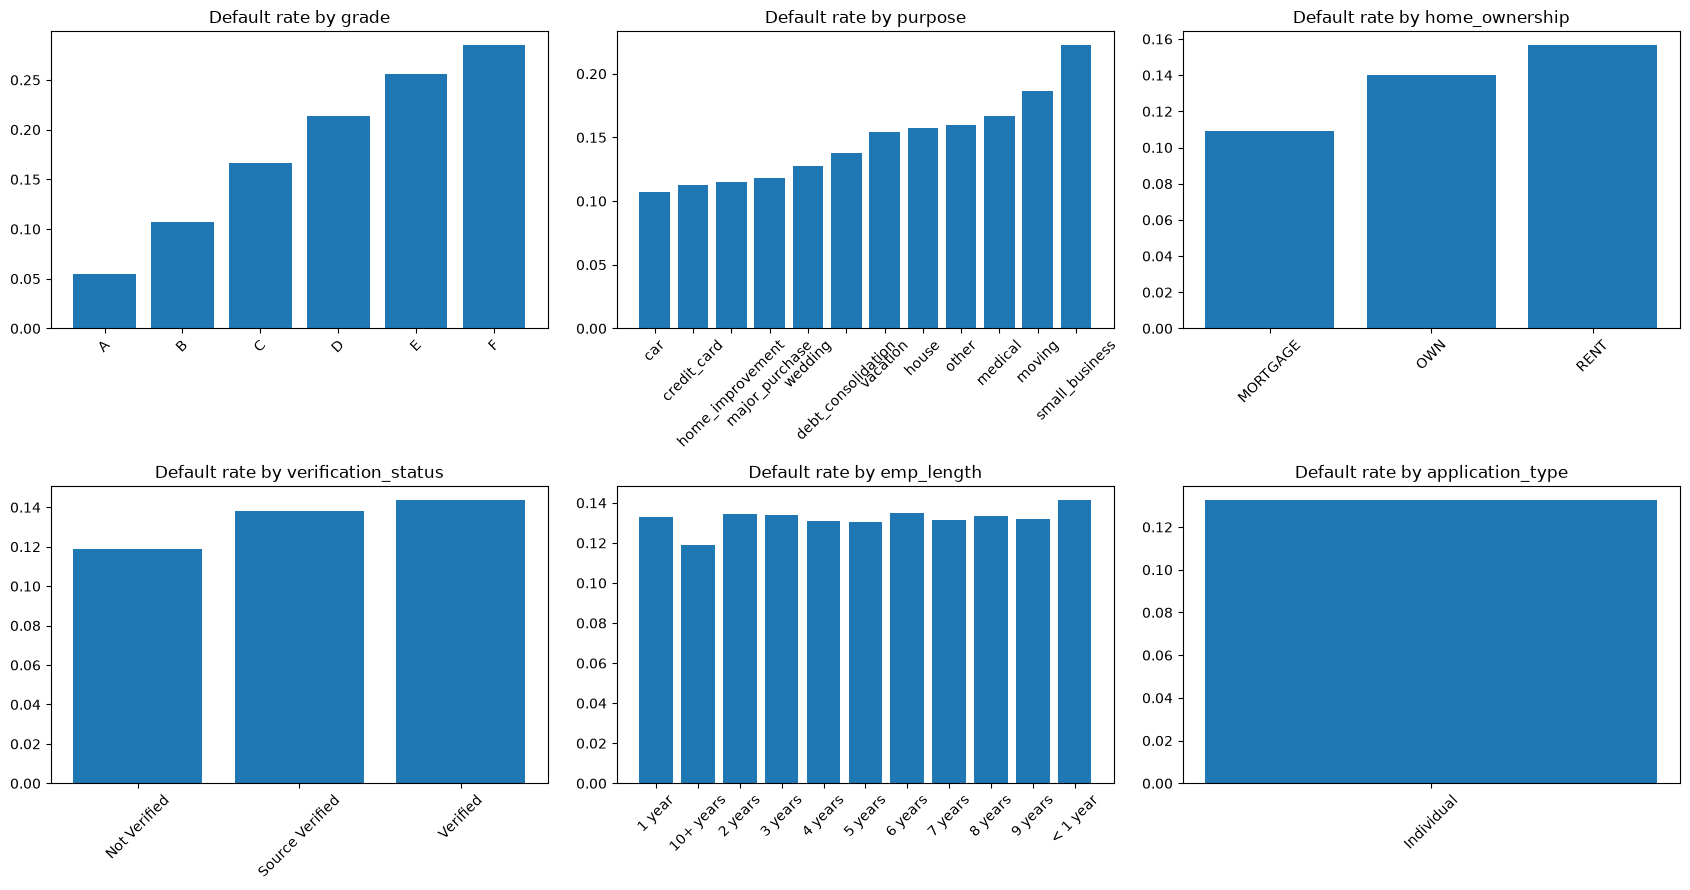

In [29]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), ['grade', 'purpose', 'home_ownership', 'verification_status', 'emp_length', 'application_type']):
    g = dev.groupby(c)['default_flag'].agg(['mean', 'count'])
    g = g[g['count'] >= 500]
    if c not in ('grade', 'emp_length'):
        g = g.sort_values('mean')
    ax.bar(g.index.astype(str), g['mean'])
    ax.set_title(f'Default rate by {c}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [30]:
key = [c for c in ['loan_amnt', 'annual_inc', 'dti', 'revol_util', 'fico_range_low', 'open_acc', 'revol_bal'] if c in dev.columns]
print(dev[key].describe(percentiles=[.01, .5, .99]).T.round(1))
print()
print(dev.isna().mean().sort_values(ascending=False).head(12).round(3))

                   count     mean      std     min       1%      50%  \
loan_amnt       306462.0  12484.2   7588.1  1000.0   1600.0  10000.0   
annual_inc      306462.0  71257.3  55960.9  3000.0  18000.0  60000.0   
dti             306462.0     17.2      7.9     0.0      2.0     16.7   
revol_util      306288.0     55.7     23.2     0.0      3.2     56.7   
fico_range_low  306462.0    694.5     30.3   660.0    660.0    690.0   
open_acc        306462.0     11.1      4.9     0.0      3.0     10.0   
revol_bal       306462.0  15167.3  20296.7     0.0    430.6  10847.0   

                     99%        max  
loan_amnt        35000.0    35000.0  
annual_inc      244000.0  7500000.0  
dti                 34.6       40.0  
revol_util          97.6      892.3  
fico_range_low     795.0      845.0  
open_acc            26.0       84.0  
revol_bal        77588.2  2568995.0  

mths_since_recent_inq    0.123
mo_sin_old_il_acct       0.110
num_tl_120dpd_2m         0.095
pct_tl_nvr_dlq           

In [31]:
blk = ['avg_cur_bal', 'tot_cur_bal', 'mths_since_recent_inq', 'mo_sin_old_il_acct']
print(dev.groupby('issue_year')[blk].apply(lambda d: d.isna().mean()).round(3))
print()
for c in blk:
    print(c, dev.groupby(dev[c].isna())['default_flag'].mean().round(3).to_dict())

            avg_cur_bal  tot_cur_bal  mths_since_recent_inq  \
issue_year                                                    
2012              0.519        0.519                  0.251   
2013              0.000        0.000                  0.112   
2014              0.000        0.000                  0.095   

            mo_sin_old_il_acct  
issue_year                      
2012                     0.543  
2013                     0.043  
2014                     0.036  

avg_cur_bal {False: 0.132, True: 0.141}
tot_cur_bal {False: 0.132, True: 0.141}
mths_since_recent_inq {False: 0.137, True: 0.103}
mo_sin_old_il_acct {False: 0.131, True: 0.148}


In [32]:
caps = {'annual_inc': dev['annual_inc'].quantile(0.99),
        'revol_bal': dev['revol_bal'].quantile(0.99),
        'revol_util': 100}
for c, v in caps.items():
    dev[c] = dev[c].clip(upper=v)
    oot[c] = oot[c].clip(upper=v)
print(caps)

{'annual_inc': np.float64(244000.0), 'revol_bal': np.float64(77588.24000000022), 'revol_util': 100}


In [33]:
dev.to_parquet(root / 'dev_clean.parquet')
oot.to_parquet(root / 'oot_clean.parquet')
print('saved')

saved


In [34]:
for d in (dev, oot):
    yr = pd.to_datetime(d['earliest_cr_line'], format='%b-%Y', errors='coerce').dt.year
    d['credit_hist_years'] = d['issue_year'] - yr
print(dev['credit_hist_years'].describe().round(1))

count    306462.0
mean         15.8
std           7.4
min           3.0
25%          11.0
50%          14.0
75%          19.0
max          66.0
Name: credit_hist_years, dtype: float64


In [35]:
def iv_table(df, col, target='default_flag', bins=10):
    s = df[col]
    if pd.api.types.is_numeric_dtype(s):
        b = pd.qcut(s, q=bins, duplicates='drop').astype(object)
        b = b.where(s.notna(), 'Missing')
    else:
        b = s.fillna('Missing').astype(str)
        rare = b.value_counts(normalize=True)
        b = b.where(b.map(rare) >= 0.01, 'Other')
    t = pd.DataFrame({'bin': b, 'bad': df[target]}).groupby('bin', observed=True)['bad'].agg(['sum', 'count'])
    t['bad'] = t['sum']; t['good'] = t['count'] - t['sum']
    B, G = t['bad'].sum(), t['good'].sum()
    t['woe'] = np.log(((t['good'] + 0.5) / G) / ((t['bad'] + 0.5) / B))
    t['iv'] = ((t['good'] / G) - (t['bad'] / B)) * t['woe']
    return t['iv'].sum()

skip = ['issue_d', 'issue_year', 'default_flag', 'earliest_cr_line']
cand_cols = [c for c in dev.columns if c not in skip]
iv = pd.Series({c: iv_table(dev, c) for c in cand_cols}).sort_values(ascending=False)
print(iv.round(3).head(30))

sub_grade                0.305
int_rate                 0.286
grade                    0.273
fico_range_low           0.132
fico_range_high          0.132
annual_inc               0.087
bc_open_to_buy           0.078
tot_hi_cred_lim          0.071
total_bc_limit           0.070
avg_cur_bal              0.065
tot_cur_bal              0.058
acc_open_past_24mths     0.055
total_rev_hi_lim         0.053
dti                      0.048
num_tl_op_past_12m       0.043
home_ownership           0.039
mort_acc                 0.038
percent_bc_gt_75         0.036
mo_sin_rcnt_tl           0.035
mo_sin_rcnt_rev_tl_op    0.032
bc_util                  0.031
mths_since_recent_inq    0.030
mo_sin_old_rev_tl_op     0.030
mths_since_recent_bc     0.030
purpose                  0.022
revol_util               0.021
inq_last_6mths           0.020
credit_hist_years        0.020
num_actv_rev_tl          0.019
num_rev_tl_bal_gt_0      0.019
dtype: float64


In [36]:
bench = ['grade', 'sub_grade', 'int_rate']
print(iv[bench].round(3))

grade        0.273
sub_grade    0.305
int_rate     0.286
dtype: float64


In [37]:
pool = iv[(iv >= 0.02) & (iv <= 0.5)].drop(labels=bench, errors='ignore')
num_pool = [c for c in pool.index if pd.api.types.is_numeric_dtype(dev[c])]
corr = dev[num_pool].corr().abs()

shortlist = []
for c in pool.index:
    if c in num_pool and any(corr.loc[c, k] > 0.8 for k in shortlist if k in num_pool):
        continue
    shortlist.append(c)
print(len(shortlist), 'variables:')
print(iv[shortlist].round(3))

19 variables:
fico_range_low           0.132
annual_inc               0.087
bc_open_to_buy           0.078
tot_hi_cred_lim          0.071
acc_open_past_24mths     0.055
total_rev_hi_lim         0.053
dti                      0.048
num_tl_op_past_12m       0.043
home_ownership           0.039
mort_acc                 0.038
percent_bc_gt_75         0.036
mo_sin_rcnt_tl           0.035
mo_sin_rcnt_rev_tl_op    0.032
mths_since_recent_inq    0.030
mo_sin_old_rev_tl_op     0.030
mths_since_recent_bc     0.030
purpose                  0.022
revol_util               0.021
inq_last_6mths           0.020
dtype: float64


In [38]:
chk = ['avg_cur_bal', 'bc_open_to_buy', 'tot_hi_cred_lim', 'mths_since_recent_inq']
print(dev.groupby('issue_year')[chk].apply(lambda d: d.isna().mean()).round(3))

            avg_cur_bal  bc_open_to_buy  tot_hi_cred_lim  \
issue_year                                                 
2012              0.519           0.148            0.519   
2013              0.000           0.008            0.000   
2014              0.000           0.011            0.000   

            mths_since_recent_inq  
issue_year                         
2012                        0.251  
2013                        0.112  
2014                        0.095  


In [39]:
m = dev.groupby('issue_year')[shortlist].apply(lambda d: d.isna().mean()).T.round(3)
m['gap_2012_vs_later'] = (m[2012] - m[[2013, 2014]].mean(axis=1)).round(3)
m.sort_values('gap_2012_vs_later', ascending=False).head(10)

issue_year,2012,2013,2014,gap_2012_vs_later
num_tl_op_past_12m,0.519,0.000,0.000,0.519
total_rev_hi_lim,0.519,0.000,0.000,0.519
tot_hi_cred_lim,0.519,0.000,0.000,0.519
mo_sin_rcnt_rev_tl_op,0.519,0.000,0.000,0.519
mo_sin_old_rev_tl_op,0.519,0.000,0.000,0.519
mo_sin_rcnt_tl,0.519,0.000,0.000,0.519
mths_since_recent_inq,0.251,0.112,0.095,0.148
mort_acc,0.139,0.000,0.000,0.139
acc_open_past_24mths,0.139,0.000,0.000,0.139
bc_open_to_buy,0.148,0.008,0.011,0.138


In [40]:
dev = dev[dev.issue_year >= 2013].copy()
print(len(dev), round(dev.default_flag.mean(), 3))

262992 0.132


In [41]:
iv = pd.Series({c: iv_table(dev, c) for c in cand_cols}).sort_values(ascending=False)
final = ['fico_range_low', 'annual_inc', 'bc_open_to_buy', 'tot_hi_cred_lim', 'acc_open_past_24mths',
         'dti', 'home_ownership', 'mort_acc', 'percent_bc_gt_75', 'mo_sin_rcnt_tl',
         'mths_since_recent_inq', 'mo_sin_old_rev_tl_op', 'purpose', 'revol_util', 'credit_hist_years']
print(iv[final].round(3))

fico_range_low           0.133
annual_inc               0.089
bc_open_to_buy           0.078
tot_hi_cred_lim          0.078
acc_open_past_24mths     0.057
dti                      0.052
home_ownership           0.042
mort_acc                 0.040
percent_bc_gt_75         0.035
mo_sin_rcnt_tl           0.037
mths_since_recent_inq    0.033
mo_sin_old_rev_tl_op     0.034
purpose                  0.020
revol_util               0.018
credit_hist_years        0.021
dtype: float64


In [42]:
cols_out = ['issue_year', 'default_flag'] + final + ['grade', 'sub_grade', 'int_rate']
dev[cols_out].to_parquet(root / 'sc_dev.parquet')
oot[cols_out].to_parquet(root / 'sc_oot.parquet')
print('saved', dev[cols_out].shape, oot[cols_out].shape)

saved (262992, 20) (283026, 20)


In [43]:
!pip install optbinning

   ---------------------------------------- 0.0/24.7 MB ? eta -:--:--
   ----------- ---------------------------- 7.3/24.7 MB 37.8 MB/s eta 0:00:01
   ------------------------ --------------- 15.2/24.7 MB 37.6 MB/s eta 0:00:01
   ------------------------------------- -- 23.3/24.7 MB 38.4 MB/s eta 0:00:01
   ---------------------------------------- 24.7/24.7 MB 35.8 MB/s  0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 34.7 MB/s  0:00:00
   ---------------------------------------- 0.0/674.3 kB ? eta -:--:--
   ---------------------------------------- 674.3/674.3 kB 25.8 MB/s  0:00:00
   ---------------------------------------- 0.0/887.3 kB ? eta -:--:--
   ---------------------------------------- 887.3/887.3 kB 29.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 2.8/2.8 MB 28.0 MB/s  0:00:00
   -------------------------------

In [44]:
import duckdb, pandas as pd, numpy as np
from pathlib import Path
root = Path(r"C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data")
dev = pd.read_parquet(root / 'sc_dev.parquet')
oot = pd.read_parquet(root / 'sc_oot.parquet')
final = ['fico_range_low','annual_inc','bc_open_to_buy','tot_hi_cred_lim','acc_open_past_24mths',
         'dti','home_ownership','mort_acc','percent_bc_gt_75','mo_sin_rcnt_tl',
         'mths_since_recent_inq','mo_sin_old_rev_tl_op','purpose','revol_util','credit_hist_years']
print(dev.shape, oot.shape)

(262992, 20) (283026, 20)


In [46]:
import pandas as pd, numpy as np
from pathlib import Path
root = Path(r"C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data")
dev = pd.read_parquet(root / 'sc_dev.parquet')
oot = pd.read_parquet(root / 'sc_oot.parquet')
final = ['fico_range_low','annual_inc','bc_open_to_buy','tot_hi_cred_lim','acc_open_past_24mths',
         'dti','home_ownership','mort_acc','percent_bc_gt_75','mo_sin_rcnt_tl',
         'mths_since_recent_inq','mo_sin_old_rev_tl_op','purpose','revol_util','credit_hist_years']
print(dev.shape, oot.shape)

(262992, 20) (283026, 20)


In [47]:
def woe_from_labels(labels, y):
    t = pd.DataFrame({'b': labels, 'y': y}).groupby('b')['y'].agg(['sum', 'count'])
    t['bad'] = t['sum']; t['good'] = t['count'] - t['sum']
    B, G = t['bad'].sum(), t['good'].sum()
    t['woe'] = np.log(((t['good'] + 0.5) / G) / ((t['bad'] + 0.5) / B))
    t['iv'] = ((t['good'] / G) - (t['bad'] / B)) * t['woe']
    t['bad_rate'] = t['bad'] / t['count']
    return t

def fit_numeric(x, y, start_bins=10, max_bins=8):
    x = pd.Series(x).astype(float).reset_index(drop=True)
    y = np.asarray(y)
    ok = x.notna().values
    edges = np.unique(np.quantile(x[ok], np.linspace(0, 1, start_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    def rates(e):
        b = np.digitize(x[ok], e[1:-1])
        d = pd.DataFrame({'b': b, 'y': y[ok]}).groupby('b')['y'].agg(['sum', 'count'])
        return (d['sum'] / d['count']).values
    r = rates(edges)
    inc = np.corrcoef(np.arange(len(r)), r)[0, 1] >= 0 if len(r) > 1 else True
    while len(edges) > 2:
        r = rates(edges)
        viol = [i for i in range(len(r) - 1) if (r[i] > r[i + 1] if inc else r[i] < r[i + 1])]
        if not viol and len(r) <= max_bins:
            break
        i = viol[0] if viol else int(np.argmin(np.abs(np.diff(r))))
        edges = np.delete(edges, i + 1)
    return edges

def label_numeric(x, edges):
    x = pd.Series(x).astype(float)
    return pd.Series(np.where(x.isna(), -1, np.digitize(x.fillna(0), edges[1:-1])), index=x.index)

def fit_variable(x, y, is_num):
    if is_num:
        edges = fit_numeric(x, y)
        t = woe_from_labels(label_numeric(x, edges).values, y)
        return {'num': True, 'edges': edges, 'woe': t['woe'].to_dict(), 'table': t, 'iv': t['iv'].sum()}
    s = pd.Series(x).fillna('Missing').astype(str)
    share = s.value_counts(normalize=True)
    keep = set(share[share >= 0.02].index)
    lab = s.where(s.isin(keep), 'Other')
    t = woe_from_labels(lab.values, y)
    return {'num': False, 'keep': keep, 'woe': t['woe'].to_dict(), 'table': t, 'iv': t['iv'].sum()}

def transform_variable(x, m):
    if m['num']:
        lab = label_numeric(x, m['edges'])
    else:
        s = pd.Series(x).fillna('Missing').astype(str)
        lab = s.where(s.isin(m['keep']), 'Other')
    return lab.map(m['woe']).fillna(0.0).values

In [48]:
ydev = dev['default_flag'].values
models = {v: fit_variable(dev[v].values, ydev, pd.api.types.is_numeric_dtype(dev[v])) for v in final}
summary = pd.DataFrame({'variable': list(models), 'iv': [round(m['iv'], 3) for m in models.values()],
                        'bins': [len(m['table']) for m in models.values()]}).sort_values('iv', ascending=False)
print(summary)

                 variable     iv  bins
0          fico_range_low  0.131     8
1              annual_inc  0.088     8
2          bc_open_to_buy  0.078     9
3         tot_hi_cred_lim  0.078     8
4    acc_open_past_24mths  0.057     8
5                     dti  0.052     8
7                mort_acc  0.047     5
6          home_ownership  0.042     4
9          mo_sin_rcnt_tl  0.037     8
8        percent_bc_gt_75  0.035     8
11   mo_sin_old_rev_tl_op  0.034     8
10  mths_since_recent_inq  0.033     9
14      credit_hist_years  0.022     8
13             revol_util  0.018     9
12                purpose  0.015     5


In [49]:
models['fico_range_low']['table'][['count', 'bad_rate', 'woe']].round(3)

,count,bad_rate,woe
b,,,
0,24782,0.183,-0.387
1,48940,0.169,-0.291
2,42914,0.155,-0.190
3,36866,0.138,-0.049
4,16273,0.128,0.038
5,38105,0.109,0.213
6,28717,0.084,0.499
7,26395,0.056,0.935


In [50]:
models['purpose']['table'][['count', 'bad_rate', 'woe']].round(3)

,count,bad_rate,woe
b,,,
Other,17375,0.156,-0.198
credit_card,66200,0.112,0.184
debt_consolidation,152387,0.137,-0.042
home_improvement,14093,0.116,0.143
other,12937,0.159,-0.219


In [51]:
yoot = oot['default_flag'].values
X_dev = pd.DataFrame({v: transform_variable(dev[v].values, models[v]) for v in final})
X_oot = pd.DataFrame({v: transform_variable(oot[v].values, models[v]) for v in final})
X_dev.assign(default_flag=ydev).to_parquet(root / 'woe_dev.parquet')
X_oot.assign(default_flag=yoot).to_parquet(root / 'woe_oot.parquet')
pd.concat({v: m['table'] for v, m in models.items()}).to_csv(root / 'bin_tables.csv')
print(X_dev.shape, X_oot.shape)

(262992, 15) (283026, 15)


In [52]:
import pandas as pd, numpy as np
from pathlib import Path
root = Path(r"C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data")
wd = pd.read_parquet(root / 'woe_dev.parquet'); wo = pd.read_parquet(root / 'woe_oot.parquet')
X_dev, ydev = wd.drop(columns='default_flag'), wd['default_flag'].values
X_oot, yoot = wo.drop(columns='default_flag'), wo['default_flag'].values
print(X_dev.shape, X_oot.shape)

(262992, 15) (283026, 15)


In [53]:
import statsmodels.api as sm
res = sm.Logit(ydev, sm.add_constant(X_dev)).fit(disp=0)
coef = pd.DataFrame({'coef': res.params, 'p_value': res.pvalues}).round(4)
print(coef)

                         coef  p_value
const                 -1.8873   0.0000
fico_range_low        -0.5309   0.0000
annual_inc            -0.5411   0.0000
bc_open_to_buy        -0.1840   0.0000
tot_hi_cred_lim       -0.3882   0.0000
acc_open_past_24mths  -0.7851   0.0000
dti                   -0.6162   0.0000
home_ownership        -0.2928   0.0000
mort_acc              -0.1383   0.0005
percent_bc_gt_75      -0.3931   0.0000
mo_sin_rcnt_tl        -0.3510   0.0000
mths_since_recent_inq -0.6871   0.0000
mo_sin_old_rev_tl_op  -0.5600   0.0000
purpose               -0.7791   0.0000
revol_util            -0.3277   0.0000
credit_hist_years      0.4059   0.0000


In [54]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xc = sm.add_constant(X_dev)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X_dev.columns).round(2)
print(vif.sort_values(ascending=False))

mo_sin_old_rev_tl_op     3.67
credit_hist_years        3.64
tot_hi_cred_lim          2.79
mort_acc                 2.22
revol_util               2.17
bc_open_to_buy           2.06
percent_bc_gt_75         2.04
home_ownership           1.96
annual_inc               1.75
fico_range_low           1.63
acc_open_past_24mths     1.56
mo_sin_rcnt_tl           1.49
dti                      1.24
mths_since_recent_inq    1.20
purpose                  1.03
dtype: float64


In [55]:
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

def metrics(y, p):
    auc = roc_auc_score(y, p)
    return {'AUC': round(auc, 3), 'Gini': round(2 * auc - 1, 3), 'KS': round(float(ks_2samp(p[y == 1], p[y == 0]).statistic), 3)}

pd_dev = res.predict(sm.add_constant(X_dev)).values
pd_oot = res.predict(sm.add_constant(X_oot)).values
print('development:', metrics(ydev, pd_dev))
print('out-of-time:', metrics(yoot, pd_oot))
print('predicted vs actual default rate (oot):', round(pd_oot.mean(), 3), round(yoot.mean(), 3))

oot_raw = pd.read_parquet(root / 'sc_oot.parquet')
print('benchmark, Lending Club interest rate (oot):', metrics(yoot, oot_raw['int_rate'].astype(float).values))

development: {'AUC': 0.658, 'Gini': 0.316, 'KS': 0.227}
out-of-time: {'AUC': 0.666, 'Gini': 0.331, 'KS': 0.239}
predicted vs actual default rate (oot): 0.135 0.149
benchmark, Lending Club interest rate (oot): {'AUC': 0.678, 'Gini': 0.357, 'KS': 0.262}


In [56]:
pdo, base_score, base_odds = 20, 600, 50      # 20 points double the odds; 600 points = 50:1 good-to-bad odds
factor = pdo / np.log(2)
offset = base_score - factor * np.log(base_odds)

lin_oot = sm.add_constant(X_oot).values @ res.params.values
score_oot = offset - factor * lin_oot
print(pd.Series(score_oot).describe().round(1))

d = pd.DataFrame({'pred': pd_oot, 'actual': yoot})
d['decile'] = pd.qcut(d['pred'], 10, labels=False, duplicates='drop') + 1
print(d.groupby('decile').agg(pred=('pred', 'mean'), actual=('actual', 'mean'), n=('actual', 'size')).round(3))

count    283026.0
mean        544.6
std          18.2
min         488.3
25%         531.5
50%         543.4
75%         556.5
max         614.4
dtype: float64
         pred  actual      n
decile                      
1       0.041   0.039  28303
2       0.065   0.071  28303
3       0.083   0.093  28302
4       0.099   0.113  28303
5       0.116   0.128  28302
6       0.134   0.151  28303
7       0.154   0.173  28302
8       0.177   0.198  28303
9       0.209   0.231  28302
10      0.273   0.293  28303


## Part 2: Challenger model

In [1]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 4.2 MB/s eta 0:00:12
   -- ------------------------------------- 3.1/48.9 MB 6.2 MB/s eta 0:00:08
   ------ --------------------------------- 8.1/48.9 MB 11.4 MB/s eta 0:00:04
   ---------- ----------------------------- 13.1/48.9 MB 14.5 MB/s eta 0:00:03
   ------------ --------------------------- 14.9/48.9 MB 13.5 MB/s eta 0:00:03
   ------------- -------------------------- 16.8/48.9 MB 12.8 MB/s eta 0:00:03
   -------------- ------------------------- 18.4/48.9 MB 11.8 MB/s eta 0:00:03
   ----------------- ---------------------- 21.5/48.9 MB 12.4 MB/s eta 0:00:03
   -------------------- ------------------- 24.6/48.9 MB 12.7 MB/s eta 0:00:02
   -------------------- ------------------- 25.7/48.9 MB 12.1 MB/s eta 0:00:02
   ---------------------- ----------------- 27.0/48.9 MB 11.6 MB/s eta 0:00

In [2]:
import pandas as pd, numpy as np, statsmodels.api as sm
from pathlib import Path
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

root = Path(r"C:\Users\ANTARA BASAK\Documents\risk-projects\a1-pd-scorecard\data")
wd = pd.read_parquet(root / 'woe_dev.parquet'); wo = pd.read_parquet(root / 'woe_oot.parquet')
X_dev, ydev = wd.drop(columns='default_flag'), wd['default_flag'].values
X_oot, yoot = wo.drop(columns='default_flag'), wo['default_flag'].values

res = sm.Logit(ydev, sm.add_constant(X_dev)).fit(disp=0)
pd_dev = res.predict(sm.add_constant(X_dev)).values
pd_oot = res.predict(sm.add_constant(X_oot)).values

def metrics(y, p):
    auc = roc_auc_score(y, p)
    return {'AUC': round(auc, 3), 'Gini': round(2 * auc - 1, 3), 'KS': round(float(ks_2samp(p[y == 1], p[y == 0]).statistic), 3)}

print('development:', metrics(ydev, pd_dev))
print('out-of-time:', metrics(yoot, pd_oot))

development: {'AUC': 0.658, 'Gini': 0.316, 'KS': 0.227}
out-of-time: {'AUC': 0.666, 'Gini': 0.331, 'KS': 0.239}


In [3]:
final = ['fico_range_low','annual_inc','bc_open_to_buy','tot_hi_cred_lim','acc_open_past_24mths',
         'dti','home_ownership','mort_acc','percent_bc_gt_75','mo_sin_rcnt_tl',
         'mths_since_recent_inq','mo_sin_old_rev_tl_op','purpose','revol_util','credit_hist_years']
raw_dev = pd.read_parquet(root / 'sc_dev.parquet'); raw_oot = pd.read_parquet(root / 'sc_oot.parquet')
cat_cols = [c for c in final if not pd.api.types.is_numeric_dtype(raw_dev[c])]
cats = {c: raw_dev[c].astype('category').cat.categories for c in cat_cols}

def prep(d):
    X = d[final].copy()
    for c in cat_cols:
        codes = pd.Categorical(X[c], categories=cats[c]).codes.astype(float)
        X[c] = np.where(codes < 0, np.nan, codes)
    return X

Xd, Xo = prep(raw_dev), prep(raw_oot)
print(Xd.shape, Xo.shape)

(262992, 15) (283026, 15)


C:\Users\ANTARA BASAK\AppData\Local\Temp\ipykernel_9404\2446815064.py:11: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  codes = pd.Categorical(X[c], categories=cats[c]).codes.astype(float)


In [4]:
import xgboost as xgb
idx = np.random.default_rng(0).permutation(len(Xd)); cut = int(len(idx) * 0.8)
tr, va = idx[:cut], idx[cut:]
model = xgb.XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=4, subsample=0.8,
                          colsample_bytree=0.8, min_child_weight=50, reg_lambda=5,
                          eval_metric='auc', early_stopping_rounds=30, n_jobs=-1, random_state=42)
model.fit(Xd.iloc[tr], ydev[tr], eval_set=[(Xd.iloc[va], ydev[va])], verbose=False)
print('stopped at tree', model.best_iteration)

stopped at tree 452


In [5]:
px_dev = model.predict_proba(Xd)[:, 1]; px_oot = model.predict_proba(Xo)[:, 1]
bm = raw_oot['int_rate'].astype(float).values
table = pd.DataFrame({
    'Scorecard (logistic on WoE)': [metrics(ydev, pd_dev)['Gini'], metrics(yoot, pd_oot)['Gini'], metrics(ydev, pd_dev)['KS'], metrics(yoot, pd_oot)['KS']],
    'XGBoost challenger':          [metrics(ydev, px_dev)['Gini'], metrics(yoot, px_oot)['Gini'], metrics(ydev, px_dev)['KS'], metrics(yoot, px_oot)['KS']],
    'Benchmark: LC interest rate': [np.nan, metrics(yoot, bm)['Gini'], np.nan, metrics(yoot, bm)['KS']],
}, index=['Gini dev', 'Gini oot', 'KS dev', 'KS oot']).T
print(table)
print('predicted vs actual default rate (oot): scorecard', round(pd_oot.mean(), 3), '| xgboost', round(px_oot.mean(), 3), '| actual', round(yoot.mean(), 3))

                             Gini dev  Gini oot  KS dev  KS oot
Scorecard (logistic on WoE)     0.316     0.331   0.227   0.239
XGBoost challenger              0.376     0.351   0.272   0.253
Benchmark: LC interest rate       NaN     0.357     NaN   0.262
predicted vs actual default rate (oot): scorecard 0.135 | xgboost 0.137 | actual 0.149


In [6]:
!pip install shap

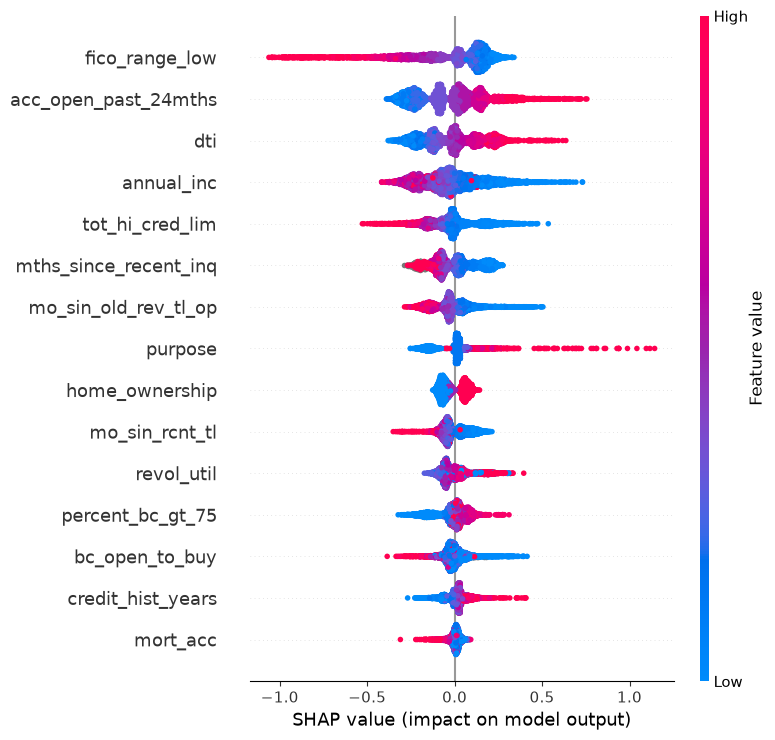

In [7]:
import shap, matplotlib.pyplot as plt
sample = Xd.sample(5000, random_state=0)
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(sample)
shap.summary_plot(sv, sample, show=False)
plt.tight_layout()
plt.savefig(root.parent / 'outputs' / 'shap_summary.png', dpi=150)
plt.show()

In [8]:
imp = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False).round(4)
print(imp)

fico_range_low           0.1979
acc_open_past_24mths     0.1604
dti                      0.1399
annual_inc               0.1363
tot_hi_cred_lim          0.1055
mths_since_recent_inq    0.1054
mo_sin_old_rev_tl_op     0.0813
purpose                  0.0723
home_ownership           0.0639
mo_sin_rcnt_tl           0.0627
revol_util               0.0619
percent_bc_gt_75         0.0606
bc_open_to_buy           0.0481
credit_hist_years        0.0443
mort_acc                 0.0209
dtype: float32


In [9]:
print(pd.DataFrame({'coef': res.params, 'p_value': res.pvalues}).round(4))

                         coef  p_value
const                 -1.8873   0.0000
fico_range_low        -0.5309   0.0000
annual_inc            -0.5411   0.0000
bc_open_to_buy        -0.1840   0.0000
tot_hi_cred_lim       -0.3882   0.0000
acc_open_past_24mths  -0.7851   0.0000
dti                   -0.6162   0.0000
home_ownership        -0.2928   0.0000
mort_acc              -0.1383   0.0005
percent_bc_gt_75      -0.3931   0.0000
mo_sin_rcnt_tl        -0.3510   0.0000
mths_since_recent_inq -0.6871   0.0000
mo_sin_old_rev_tl_op  -0.5600   0.0000
purpose               -0.7791   0.0000
revol_util            -0.3277   0.0000
credit_hist_years      0.4059   0.0000


In [10]:
model.save_model(str(root / 'xgb_challenger.json'))
print('saved')

saved


In [11]:
def psi(expected, actual, bins=10):
    expected, actual = pd.Series(expected).reset_index(drop=True), pd.Series(actual).reset_index(drop=True)
    if pd.api.types.is_numeric_dtype(expected):
        edges = np.unique(np.nanquantile(expected.astype(float), np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        lab = lambda s: pd.Series(np.where(s.isna(), -1, np.digitize(s.astype(float).fillna(0), edges[1:-1])))
        e, a = lab(expected), lab(actual)
    else:
        e, a = expected.fillna('Missing').astype(str), actual.fillna('Missing').astype(str)
    ep, ap = e.value_counts(normalize=True), a.value_counts(normalize=True)
    idx = ep.index.union(ap.index)
    ep, ap = ep.reindex(idx).fillna(0) + 1e-4, ap.reindex(idx).fillna(0) + 1e-4
    return float(((ap - ep) * np.log(ap / ep)).sum())

In [12]:
pdo, base_score, base_odds = 20, 600, 50
factor = pdo / np.log(2); offset = base_score - factor * np.log(base_odds)
score_dev = offset - factor * (sm.add_constant(X_dev).values @ res.params.values)
score_oot = offset - factor * (sm.add_constant(X_oot).values @ res.params.values)
print('Score PSI (dev vs 2015):', round(psi(score_dev, score_oot), 4))

rows = [(v, round(psi(raw_dev[v], raw_oot[v]), 4)) for v in final]
stab = pd.DataFrame(rows, columns=['variable', 'psi']).sort_values('psi', ascending=False)
stab['status'] = np.where(stab.psi < 0.10, 'stable', np.where(stab.psi < 0.25, 'moderate', 'significant'))
print(stab)

Score PSI (dev vs 2015): 0.0035
                 variable     psi  status
8        percent_bc_gt_75  0.0259  stable
5                     dti  0.0239  stable
13             revol_util  0.0211  stable
4    acc_open_past_24mths  0.0179  stable
2          bc_open_to_buy  0.0119  stable
11   mo_sin_old_rev_tl_op  0.0104  stable
3         tot_hi_cred_lim  0.0080  stable
12                purpose  0.0079  stable
7                mort_acc  0.0064  stable
14      credit_hist_years  0.0063  stable
6          home_ownership  0.0038  stable
9          mo_sin_rcnt_tl  0.0038  stable
10  mths_since_recent_inq  0.0037  stable
0          fico_range_low  0.0027  stable
1              annual_inc  0.0027  stable


In [13]:
findings = pd.DataFrame([
 ['F1', 'Calibration', 'Both models under-predict 2015 defaults: 13.5% (scorecard) and 13.7% (XGBoost) vs 14.9% actual.', 'Decile table, Cell 5 output', 'Medium', 'Recalibrate the intercept on more recent data; monitor calibration each quarter.'],
 ['F2', 'Challenger benchmarking', 'XGBoost improves out-of-time Gini by about 0.020 (0.351 vs 0.331); added complexity is not justified.', 'Comparison table', 'Low', 'Keep the scorecard as the primary model; revisit if the gap widens.'],
 ['F3', 'Stability over time', 'Challenger Gini falls from 0.376 (development) to 0.351 (2015), indicating some period sensitivity.', 'Comparison table', 'Low', 'Monitor challenger performance if it is ever promoted.'],
 ['F4', 'External benchmark', 'Scorecard trails the lender interest rate by about 0.026 Gini (0.331 vs 0.357).', 'Comparison table', 'Low', 'Informational: the rate uses information outside the 15 variables.'],
], columns=['ID', 'Area', 'Finding', 'Evidence', 'Severity', 'Recommendation'])
findings['Owner'] = 'Model developer'; findings['Status'] = 'Open'
findings.to_csv(root.parent / 'outputs' / 'findings_log.csv', index=False)
findings

,ID,Area,Finding,Evidence,Severity,Recommendation,Owner,Status
0,F1,Calibration,Both models under-predict 2015 defaults: 13.5%...,"Decile table, Cell 5 output",Medium,Recalibrate the intercept on more recent data;...,Model developer,Open
1,F2,Challenger benchmarking,XGBoost improves out-of-time Gini by about 0.0...,Comparison table,Low,Keep the scorecard as the primary model; revis...,Model developer,Open
2,F3,Stability over time,Challenger Gini falls from 0.376 (development)...,Comparison table,Low,Monitor challenger performance if it is ever p...,Model developer,Open
3,F4,External benchmark,Scorecard trails the lender interest rate by a...,Comparison table,Low,Informational: the rate uses information outsi...,Model developer,Open


In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xc = sm.add_constant(X_dev)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X_dev.columns).round(2)
print(vif.sort_values(ascending=False))
print(X_dev.corr()['credit_hist_years'].drop('credit_hist_years').sort_values(ascending=False).round(2).head(4))

mo_sin_old_rev_tl_op     3.67
credit_hist_years        3.64
tot_hi_cred_lim          2.79
mort_acc                 2.22
revol_util               2.17
bc_open_to_buy           2.06
percent_bc_gt_75         2.04
home_ownership           1.96
annual_inc               1.75
fico_range_low           1.63
acc_open_past_24mths     1.56
mo_sin_rcnt_tl           1.49
dti                      1.24
mths_since_recent_inq    1.20
purpose                  1.03
dtype: float64
mo_sin_old_rev_tl_op    0.85
mort_acc                0.37
annual_inc              0.26
tot_hi_cred_lim         0.26
Name: credit_hist_years, dtype: float64


In [15]:
keep_vars = [c for c in X_dev.columns if c != 'credit_hist_years']
res2 = sm.Logit(ydev, sm.add_constant(X_dev[keep_vars])).fit(disp=0)
print(pd.DataFrame({'coef': res2.params, 'p_value': res2.pvalues}).round(4))
pd2_dev = res2.predict(sm.add_constant(X_dev[keep_vars])).values
pd2_oot = res2.predict(sm.add_constant(X_oot[keep_vars])).values
print('dev:', metrics(ydev, pd2_dev)); print('oot:', metrics(yoot, pd2_oot))
print('predicted vs actual (oot):', round(pd2_oot.mean(), 3), round(yoot.mean(), 3))

                         coef  p_value
const                 -1.8874    0.000
fico_range_low        -0.5312    0.000
annual_inc            -0.5312    0.000
bc_open_to_buy        -0.1872    0.000
tot_hi_cred_lim       -0.3954    0.000
acc_open_past_24mths  -0.7854    0.000
dti                   -0.6205    0.000
home_ownership        -0.2855    0.000
mort_acc              -0.1173    0.003
percent_bc_gt_75      -0.3923    0.000
mo_sin_rcnt_tl        -0.3549    0.000
mths_since_recent_inq -0.6856    0.000
mo_sin_old_rev_tl_op  -0.3003    0.000
purpose               -0.7801    0.000
revol_util            -0.3278    0.000
dev: {'AUC': 0.658, 'Gini': 0.316, 'KS': 0.227}
oot: {'AUC': 0.665, 'Gini': 0.331, 'KS': 0.239}
predicted vs actual (oot): 0.135 0.149


In [16]:
out = root.parent / 'outputs'
pd.DataFrame({'coef': res2.params, 'p_value': res2.pvalues}).round(4).to_csv(out / 'final_scorecard_coefficients.csv')
stab.to_csv(out / 'stability_psi.csv', index=False)
print('saved')

saved


In [17]:
new = pd.DataFrame([['F5', 'Variable selection',
   'Wrong-sign coefficient on credit_hist_years (+0.406) caused by overlap (correlation 0.85) with mo_sin_old_rev_tl_op; variable removed and the model refitted with no loss of performance (Gini 0.316 / 0.331 unchanged).',
   'Cells 9, 14, 15', 'Low', 'Closed during development; keep correlation screening in the build procedure.', 'Model developer', 'Closed']],
   columns=findings.columns)
findings = pd.concat([findings, new], ignore_index=True)
findings.to_csv(out / 'findings_log.csv', index=False)
findings[['ID', 'Area', 'Severity', 'Status']]

,ID,Area,Severity,Status
0,F1,Calibration,Medium,Open
1,F2,Challenger benchmarking,Low,Open
2,F3,Stability over time,Low,Open
3,F4,External benchmark,Low,Open
4,F5,Variable selection,Low,Closed


In [1]:
import os
print(os.getcwd())
os.startfile(os.getcwd())

C:\Users\ANTARA BASAK
